# 05_c — Análise da série longa: repasses × riqueza e pobreza dos municípios (2004–2025)

**Pergunta central:** os repasses obrigatórios do Governo do RN (ICMS, IPVA, IPI e Royalties) chegam mais a
municípios ricos ou pobres? E isso mudou ao longo de 20 anos?

**Perguntas de pesquisa**
1. Quão desigual é a distribuição dos repasses por habitante, e essa desigualdade mudou ao longo do tempo?
2. Municípios mais pobres recebem mais ou menos por habitante?
3. Há concentração dos repasses em determinadas regiões ou portes de município?

**Entradas** (lidas do GitHub, saídas dos notebooks anteriores):
- `repasses_2004_2025.csv` (05_a) e `indicadores_2004_2025.csv` (05_b).

**Duas réguas de riqueza/pobreza**, porque uma só não basta:

| Medida | Anos | O que mede |
|---|---|---|
| **PIB per capita** | 2004–2023 | **Riqueza produzida** no território (inclui petróleo, eólicas, sal) |
| **% da população em baixa renda no CadÚnico** | 2020–2025 | **Pobreza das pessoas** que moram no município |

Elas podem discordar: um município com parque eólico tem PIB per capita altíssimo, mas a renda dessa produção
vai para as empresas, e a população pode continuar pobre.

**Cuidados na leitura**
- Valores corrigidos pela inflação, em **reais de 2025** (fator IPCA do 05_b).
- **2011:** só há ICMS; o total dos repasses fica vazio. Por isso várias análises usam o **ICMS**, que existe
  em todos os anos e representa cerca de 85% dos repasses.
- **PIB** vai até 2023; **CadÚnico** de 2020 a 2025 (API do MDS fora do ar desde 21/10/2026).
- **População** de cada ano: os Censos (2010, 2022) e as revisões do IBGE (2013, 2018) criam "degraus" nos
  valores per capita que não são mudanças reais.

## 1. Bibliotecas e estilo dos gráficos

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

RAW_GITHUB = 'https://raw.githubusercontent.com/Renata-Nascimento/Projeto-U02-CD/main/'
ANO_PRECOS = 2025
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Paleta: cores em ordem fixa (cada série sempre com a mesma cor) e textos em tons de cinza
AZUL, LARANJA, VERDE, AMARELO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
TEXTO, TEXTO_2, GRADE = '#0b0b0b', '#52514e', '#e5e4e0'

plt.rcParams.update({
    'figure.figsize': (10, 5), 'figure.dpi': 110, 'figure.facecolor': 'white',
    'axes.edgecolor': GRADE, 'axes.labelcolor': TEXTO_2, 'axes.titlecolor': TEXTO,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRADE, 'grid.linewidth': 0.8,
    'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2, 'lines.linewidth': 2,
    'legend.frameon': False, 'font.size': 10,
})

def reais(x, _=None):
    """Formata eixo em reais: 1500 -> 'R$ 1,5 mil' | 2_300_000_000 -> 'R$ 2,3 bi'."""
    for limite, sufixo in [(1e9, ' bi'), (1e6, ' mi'), (1e3, ' mil')]:
        if abs(x) >= limite:
            v = x / limite
            texto = f'{v:.0f}' if v >= 10 or v == int(v) else f'{v:.1f}'.replace('.', ',')
            return f'R$ {texto}{sufixo}'
    return f'R$ {x:.0f}'

def eixo_anos(ax):
    """Eixo x só com anos inteiros."""
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

def eixo_log_reais(eixo, marcas):
    """Eixo em escala log com marcas legíveis em reais."""
    eixo.set_major_locator(mticker.FixedLocator(marcas))
    eixo.set_major_formatter(mticker.FuncFormatter(reais))
    eixo.set_minor_formatter(mticker.NullFormatter())

MARCAS_REPASSE = [200, 500, 1_000, 2_000, 5_000, 10_000]
MARCAS_PIB = [10_000, 20_000, 50_000, 100_000, 200_000]

## 2. Leitura dos dados

In [24]:
repasses = pd.read_csv(RAW_GITHUB + 'saida/repasses_2004_2025.csv')
indicadores = pd.read_csv(RAW_GITHUB + 'saida/indicadores_2004_2025.csv')
municipios = pd.read_csv(RAW_GITHUB + 'dados/ibge/municipios_rn.csv')
print('repasses:', repasses.shape, '| indicadores:', indicadores.shape, '| municípios:', municipios.shape)

repasses: (14696, 7) | indicadores: (3674, 11) | municípios: (167, 6)


## 3. Montagem da base

- Repasses passam de "uma linha por tipo" para **uma coluna por tipo**.
- `rep_total` = ICMS + IPVA + IPI + Royalties (vazio em 2011, que só tem ICMS).
- Valores **reais** (× fator IPCA) e **por habitante** (÷ população do ano).
- **Porte** pela população do Censo 2022, fixo para o município não mudar de grupo ao longo da série.

**Caso atípico — PIB de Guamaré:** segundo o próprio IBGE, o PIB de Guamaré foi de R$ 702 milhões em 2010,
**negativo em 2012** (−R$ 19 milhões) e quase zero em 2013 (R$ 4 milhões), voltando a R$ 1,2 bilhão em 2015.
Isso acontece em municípios com produção e refino de petróleo: o valor adicionado da atividade pode sair negativo
nas contas regionais em anos de custo alto ou preço baixo. Não é erro de coleta, mas mostra mais uma vez como o PIB
per capita é uma régua instável para medir a riqueza da população.

**Como tratamos:** o valor real **fica na base** (inclusive o PIB per capita negativo) e o caso é marcado na coluna
`pib_atipico`. Ele só fica **de fora das análises que usam a ordem dos municípios pelo PIB** (correlações e quartis
da seção 6), onde colocaria Guamaré como o município "mais pobre" do RN em 2012. O caso é mostrado como outlier na
seção 4.4.

In [25]:
# pivot (e não pivot_table com soma): a soma do pandas transformaria os vazios de 2011 em zero
largo = (repasses.pivot(index=['cod_ibge', 'ano'], columns='tipo', values='valor')
         .rename(columns=str.lower).add_prefix('rep_').reset_index())
largo.columns.name = None
largo['rep_total'] = largo[['rep_icms', 'rep_ipva', 'rep_ipi', 'rep_royalties']].sum(axis=1, min_count=4)

base = (indicadores
        .merge(largo, on=['cod_ibge', 'ano'], how='left')
        .merge(municipios[['cod_ibge', 'mesorregiao', 'regiao_intermediaria']], on='cod_ibge', how='left'))

fator = base[f'fator_ipca_{ANO_PRECOS}']
base['rep_total_real'] = base['rep_total'] * fator
base['rep_icms_real'] = base['rep_icms'] * fator
base['pib_real'] = base['pib_mil_reais'] * 1000 * fator                    # em reais (não mais em R$ mil)

base['rep_total_pc'] = base['rep_total_real'] / base['populacao']
base['rep_icms_pc'] = base['rep_icms_real'] / base['populacao']
base['pib_pc'] = base['pib_real'] / base['populacao']

# PIB negativo ou zero: valor real mantido, mas marcado como atípico (ver texto acima)
base['pib_atipico'] = base['pib_mil_reais'] <= 0
print('PIB negativo ou zero (marcado em pib_atipico):',
      base.loc[base['pib_atipico'], ['municipio', 'ano', 'pib_mil_reais']].to_dict('records'))
# versão usada nas análises por ordem de PIB (seção 6): sem os casos atípicos
base['pib_pc_analise'] = base['pib_pc'].where(~base['pib_atipico'])
base['pct_baixa_renda'] = base['cad_baixa_renda'] / base['populacao'] * 100

pop_2022 = base.loc[base['ano'] == 2022].set_index('cod_ibge')['populacao']
base['porte'] = pd.cut(base['cod_ibge'].map(pop_2022), bins=[0, 5_000, 10_000, 20_000, 50_000, np.inf],
                       labels=['até 5 mil', '5–10 mil', '10–20 mil', '20–50 mil', 'mais de 50 mil'])

assert len(base) == 167 * 22 and not base.duplicated(['cod_ibge', 'ano']).any()
print(base.shape)
base[['municipio', 'ano', 'populacao', 'rep_total_pc', 'rep_icms_pc', 'pib_pc', 'pct_baixa_renda', 'porte']].head()

PIB negativo ou zero (marcado em pib_atipico): [{'municipio': 'Guamaré', 'ano': 2012, 'pib_mil_reais': -19046.0}]
(3674, 28)


,municipio,ano,populacao,rep_total_pc,rep_icms_pc,pib_pc,pct_baixa_renda,porte
0,Acari,2004,11282,186.26,163.88,"8,663.87",NaN,10–20 mil
1,Acari,2005,11303,209.44,176.49,"9,178.87",NaN,10–20 mil
2,Acari,2006,11324,220.57,195.16,"9,924.50",NaN,10–20 mil
3,Acari,2007,10911,248.66,221.10,"10,878.81",NaN,10–20 mil
4,Acari,2008,11222,241.48,209.63,"11,092.67",NaN,10–20 mil


In [26]:
import os
os.makedirs('saida', exist_ok=True)
base.to_csv('saida/base_municipios_2004_2025.csv', index=False)
print('Base salva em saida/base_municipios_2004_2025.csv')

Base salva em saida/base_municipios_2004_2025.csv


## 4. Visão geral

### 4.1 Estatísticas descritivas

Três anos de referência: o início da série (2004), o meio (2013) e o último ano com PIB (2023).

In [27]:
colunas = {'rep_total_pc': 'Repasse por hab. (R$)', 'pib_pc': 'PIB por hab. (R$)',
           'pct_baixa_renda': '% baixa renda (CadÚnico)', 'populacao': 'População'}
descritivas = (base[base['ano'].isin([2004, 2013, 2023])]
               .groupby('ano')[list(colunas)].describe(percentiles=[.25, .5, .75])
               .stack(level=0, future_stack=True).rename(index=colunas)
               [['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
               .rename(columns={'mean': 'média', 'std': 'desvio', '50%': 'mediana'}))
descritivas.round(1)

média    desvio       min       25%  \
ano                                                                     
2004 Repasse por hab. (R$)       311.70    394.20    102.90    160.10   
     PIB por hab. (R$)        13,144.10 15,607.00  5,699.90  7,899.40   
     % baixa renda (CadÚnico)       NaN       NaN       NaN       NaN   
     População                17,737.20 62,771.60  1,630.00  4,300.50   
2013 Repasse por hab. (R$)       657.50  1,005.10    222.10    377.70   
     PIB por hab. (R$)        19,220.90 12,284.30    592.30 12,445.00   
     % baixa renda (CadÚnico)       NaN       NaN       NaN       NaN   
     População                20,203.30 71,500.90  1,696.00  4,518.50   
2023 Repasse por hab. (R$)     1,000.60  1,341.30    182.10    503.50   
     PIB por hab. (R$)        28,039.80 24,965.30 12,239.40 16,121.30   
     % baixa renda (CadÚnico)     62.80     10.50     32.70     55.40   
     População                20,206.00 66,390.40  1,856.00  4,488.00   

                                mediana       75%        max  
ano                                                           
2004 Repasse por hab. (R$)       220.80    300.10   3,918.20  
     PIB por hab. (R$)         8,813.70 11,012.60 149,830.40  
     % baixa renda (CadÚnico)       NaN       NaN        NaN  
     População                 7,523.00 12,115.00 766,081.00  
2013 Repasse por hab. (R$)       493.30    702.70  12,659.90  
     PIB por hab. (R$)        14,399.20 19,885.50  86,292.50  
     % baixa renda (CadÚnico)       NaN       NaN        NaN  
     População                 8,083.00 13,564.00 853,928.00  
2023 Repasse por hab. (R$)       666.10    952.00  11,743.50  
     PIB por hab. (R$)        19,113.00 28,523.70 181,158.20  
     % baixa renda (CadÚnico)     63.10     68.60      98.20  
     População                 7,942.00 12,635.50 768,334.00

Em todos os anos a **média é bem maior que a mediana** no repasse e no PIB por habitante: a distribuição é
**assimétrica**, com poucos municípios com valores muito altos puxando a média. Por isso, nas comparações entre
grupos usamos a **mediana**, e nas correlações, a de **Spearman** (que usa a ordem dos valores e não é distorcida
por esses extremos).

### 4.2 Quanto foi repassado ao longo do tempo

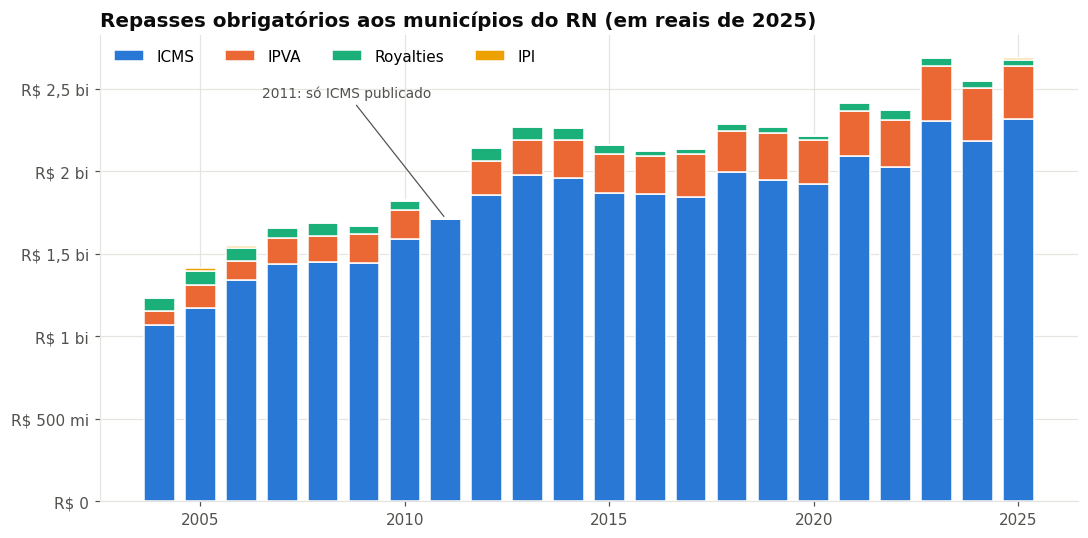

Crescimento real dos repasses de 2004 a 2023: 118%
Participação do ICMS no total (média 2004–2025, sem 2011): 86%


In [28]:
por_ano = base.groupby('ano')[['rep_icms', 'rep_ipva', 'rep_royalties', 'rep_ipi']].sum(min_count=1)
por_ano = por_ano.mul(base.groupby('ano')[f'fator_ipca_{ANO_PRECOS}'].first(), axis=0)

fig, ax = plt.subplots()
base_barra = np.zeros(len(por_ano))
for coluna, nome, cor in [('rep_icms', 'ICMS', AZUL), ('rep_ipva', 'IPVA', LARANJA),
                          ('rep_royalties', 'Royalties', VERDE), ('rep_ipi', 'IPI', AMARELO)]:
    valores = por_ano[coluna].fillna(0).values
    ax.bar(por_ano.index, valores, bottom=base_barra, color=cor, label=nome, width=0.75,
           edgecolor='white', linewidth=1)
    base_barra += valores
ax.yaxis.set_major_formatter(mticker.FuncFormatter(reais))
ax.set_title(f'Repasses obrigatórios aos municípios do RN (em reais de {ANO_PRECOS})')
ax.annotate('2011: só ICMS publicado', xy=(2011, por_ano.loc[2011, 'rep_icms']), xytext=(2006.5, 2.45e9),
            color=TEXTO_2, fontsize=9, arrowprops=dict(arrowstyle='-', color=TEXTO_2, lw=0.8))
ax.legend(ncols=4, loc='upper left')
plt.tight_layout()
plt.show()

crescimento = (por_ano.loc[2023].sum() / por_ano.loc[2004].sum() - 1) * 100
print(f'Crescimento real dos repasses de 2004 a 2023: {crescimento:.0f}%')
print(f"Participação do ICMS no total (média 2004–2025, sem 2011): "
      f"{(por_ano['rep_icms'] / por_ano.sum(axis=1)).drop(2011).mean() * 100:.0f}%")

### 4.3 Quem recebe mais em valor total

Mesmo gráfico, agora dividindo o **ICMS** (que existe em todos os anos) entre os municípios que mais recebem.
Natal, Mossoró e Parnamirim estão entre os 4 maiores em todos os anos, e Guamaré a partir de 2008. Os demais
163 municípios aparecem juntos, em cinza.

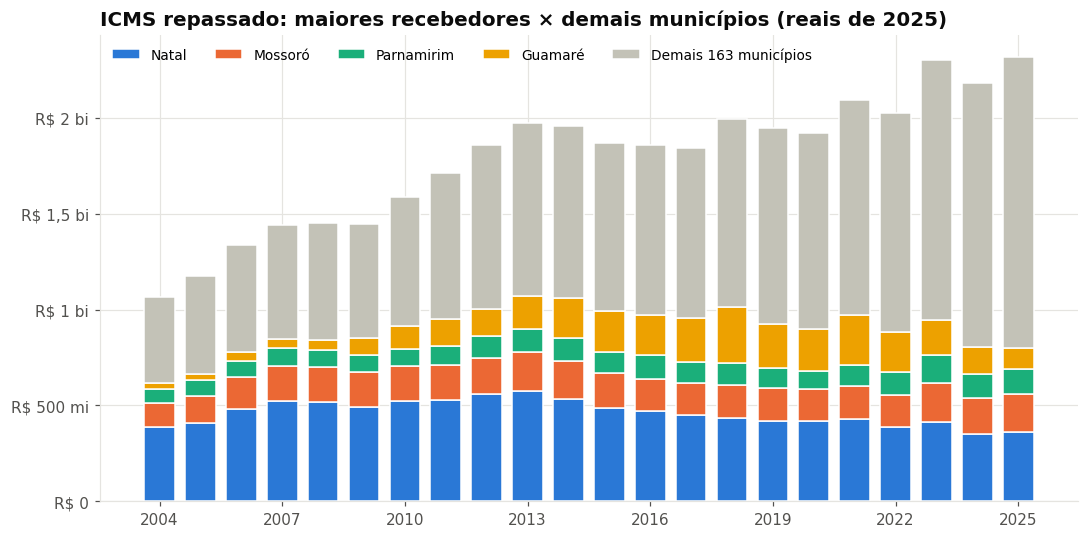

Fatia de cada um no ICMS do ano (%):


grupo,Natal,Mossoró,Parnamirim,Guamaré,Demais,4 maiores juntos
ano,,,,,,
2004,36.20,11.80,6.90,3.10,42.00,58.00
2008,35.90,12.30,6.40,3.40,42.00,58.00
2013,29.20,10.20,6.20,8.50,45.90,54.10
2018,21.90,8.50,5.70,14.60,49.30,50.70
2023,18.00,8.90,6.30,7.80,59.00,41.00
2025,15.60,8.70,5.50,4.70,65.60,34.40


In [29]:
MAIORES = ['Natal', 'Mossoró', 'Parnamirim', 'Guamaré']
CORES_MAIORES = [AZUL, LARANJA, VERDE, AMARELO]
CINZA_DEMAIS = '#c3c2b7'

icms_mun = base.assign(grupo=base['municipio'].where(base['municipio'].isin(MAIORES), 'Demais'))
icms_mun = icms_mun.pivot_table(index='ano', columns='grupo', values='rep_icms_real', aggfunc='sum')
icms_mun = icms_mun[MAIORES + ['Demais']]

fig, ax = plt.subplots()
base_barra = np.zeros(len(icms_mun))
for coluna, cor in zip(icms_mun.columns, CORES_MAIORES + [CINZA_DEMAIS]):
    rotulo = 'Demais 163 municípios' if coluna == 'Demais' else coluna
    ax.bar(icms_mun.index, icms_mun[coluna], bottom=base_barra, color=cor, label=rotulo, width=0.75,
           edgecolor='white', linewidth=1)
    base_barra += icms_mun[coluna].values
ax.yaxis.set_major_formatter(mticker.FuncFormatter(reais))
ax.set_title(f'ICMS repassado: maiores recebedores × demais municípios (reais de {ANO_PRECOS})')
ax.legend(ncols=5, loc='upper left', fontsize=9)
eixo_anos(ax)
plt.tight_layout()
plt.show()

fatia = icms_mun.div(icms_mun.sum(axis=1), axis=0) * 100
fatia['4 maiores juntos'] = fatia[MAIORES].sum(axis=1)
print('Fatia de cada um no ICMS do ano (%):')
fatia.loc[[2004, 2008, 2013, 2018, 2023, 2025]].round(1)

**Leitura:** os nomes no topo quase não mudam, mas o peso deles cai bastante. **Natal** ficava com 36% do ICMS em
2004 e com 16% em 2025; os **4 maiores juntos** passaram de 58% para 34%, e os **demais 163 municípios**, de 42%
para 66%. Guamaré chegou a 15% em 2018 e voltou a 5% em 2025.

### 4.4 Caso atípico: o PIB de Guamaré

O PIB de Guamaré (petróleo e gás) oscila muito e chegou a ficar **negativo em 2012**, enquanto o repasse que o
município recebe segue alto e estável. É um exemplo de por que o PIB, sozinho, não mede bem a riqueza da população.

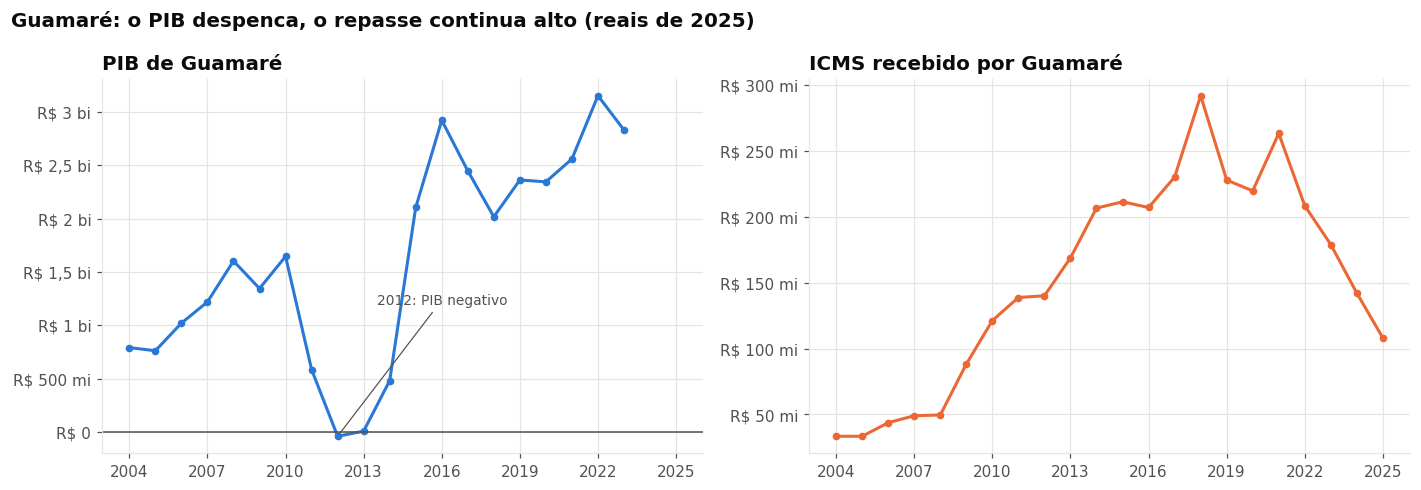

,pib_mil_reais,pib_pc,rep_icms_real,rep_total_pc
ano,,,,
2009,"546,106.00","107,075.00","88,246,149.00","7,315.00"
2010,"701,908.00","132,649.00","121,250,075.00","10,164.00"
2011,"266,331.00","45,987.00","138,708,115.00",NaN
2012,"-19,046.00","-3,045.00","140,030,089.00","11,228.00"
2013,"4,199.00",592.00,"168,754,896.00","12,660.00"
2014,"260,612.00","33,700.00","206,536,972.00","15,051.00"
2015,"1,241,923.00","143,762.00","211,306,126.00","14,893.00"
2016,"1,875,112.00","195,055.00","206,989,288.00","14,115.00"


In [30]:
guamare = base[base['municipio'] == 'Guamaré'].set_index('ano')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
axes[0].plot(guamare.index, guamare['pib_real'], color=AZUL, marker='o', markersize=4)
axes[0].axhline(0, color=TEXTO_2, lw=1)
axes[0].annotate('2012: PIB negativo', (2012, guamare.loc[2012, 'pib_real']), xytext=(2013.5, 1.2e9),
                 color=TEXTO_2, fontsize=9, arrowprops=dict(arrowstyle='-', color=TEXTO_2, lw=0.8))
axes[0].set_title('PIB de Guamaré')
axes[1].plot(guamare.index, guamare['rep_icms_real'], color=LARANJA, marker='o', markersize=4)
axes[1].set_title('ICMS recebido por Guamaré')
for ax in axes:
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(reais))
    eixo_anos(ax)
fig.suptitle(f'Guamaré: o PIB despenca, o repasse continua alto (reais de {ANO_PRECOS})',
             x=0.01, ha='left', fontsize=13, fontweight='bold', color=TEXTO)
plt.tight_layout()
plt.show()

guamare.loc[2009:2016, ['pib_mil_reais', 'pib_pc', 'rep_icms_real', 'rep_total_pc']].round(0)

## 5. Pergunta 1 — Quão desigual é o repasse por habitante?

### 5.1 Índice de Gini ao longo do tempo

O Gini vai de 0 (todos os municípios recebem o mesmo por habitante) a 1 (um município recebe tudo).
Calculamos para o total dos repasses e para o ICMS (que cobre também 2011).

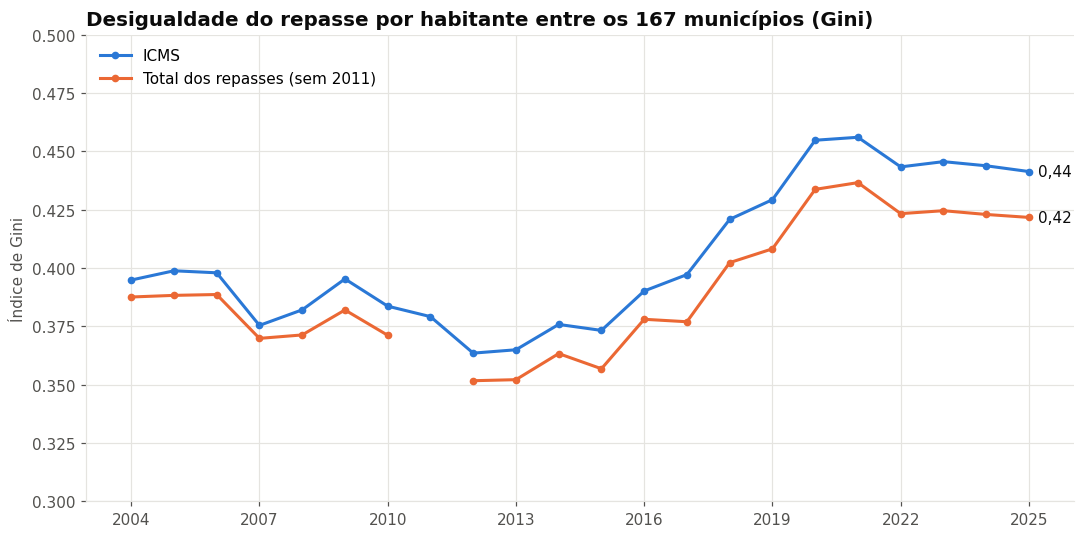

,gini_icms,gini_total,razao_p90_p10
ano,,,
2004,0.40,0.39,3.64
2008,0.38,0.37,3.57
2012,0.36,0.35,3.25
2016,0.39,0.38,3.34
2020,0.46,0.43,4.05
2023,0.45,0.42,4.03
2025,0.44,0.42,5.63


In [31]:
def gini(valores):
    x = np.sort(np.asarray(pd.Series(valores).dropna(), dtype=float))
    n = len(x)
    return np.nan if n == 0 else (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())

desigualdade = base.groupby('ano').agg(gini_total=('rep_total_pc', gini), gini_icms=('rep_icms_pc', gini),
                                       p90=('rep_total_pc', lambda s: s.quantile(.9)),
                                       p10=('rep_total_pc', lambda s: s.quantile(.1)))
desigualdade['razao_p90_p10'] = desigualdade['p90'] / desigualdade['p10']

fig, ax = plt.subplots()
ax.plot(desigualdade.index, desigualdade['gini_icms'], color=AZUL, marker='o', markersize=4, label='ICMS')
ax.plot(desigualdade.index, desigualdade['gini_total'], color=LARANJA, marker='o', markersize=4,
        label='Total dos repasses (sem 2011)')
for serie, cor in [('gini_icms', AZUL), ('gini_total', LARANJA)]:
    ax.annotate(f"{desigualdade[serie].iloc[-1]:.2f}".replace('.', ','), (desigualdade.index[-1], desigualdade[serie].iloc[-1]),
                xytext=(6, 0), textcoords='offset points', color=TEXTO, va='center')
ax.set_ylim(0.30, 0.50)
ax.set_title('Desigualdade do repasse por habitante entre os 167 municípios (Gini)')
eixo_anos(ax)
ax.set_ylabel('Índice de Gini')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

desigualdade.loc[[2004, 2008, 2012, 2016, 2020, 2023, 2025], ['gini_icms', 'gini_total', 'razao_p90_p10']].round(3)

### 5.2 Curva de Lorenz: 2004 × 2023

Imagine **todos os moradores do RN numa fila**, ordenados pelo repasse por habitante do município onde moram:
primeiro quem mora nos municípios que menos recebem por pessoa, no fim quem mora nos que mais recebem.
- **Eixo x:** quanto da fila (da população) já foi percorrido.
- **Eixo y:** quanto do dinheiro total dos repasses essa parte da fila recebe.
- **Linha tracejada:** igualdade perfeita (todos os municípios recebendo o mesmo por habitante).
- Quanto **mais longe da tracejada**, mais desigual.

**Atenção:** aqui cada município pesa pela sua **população** (a curva conta pessoas), enquanto o Gini da seção 5.1
conta **municípios** (cada um dos 167 vale igual). As duas medidas respondem perguntas diferentes.

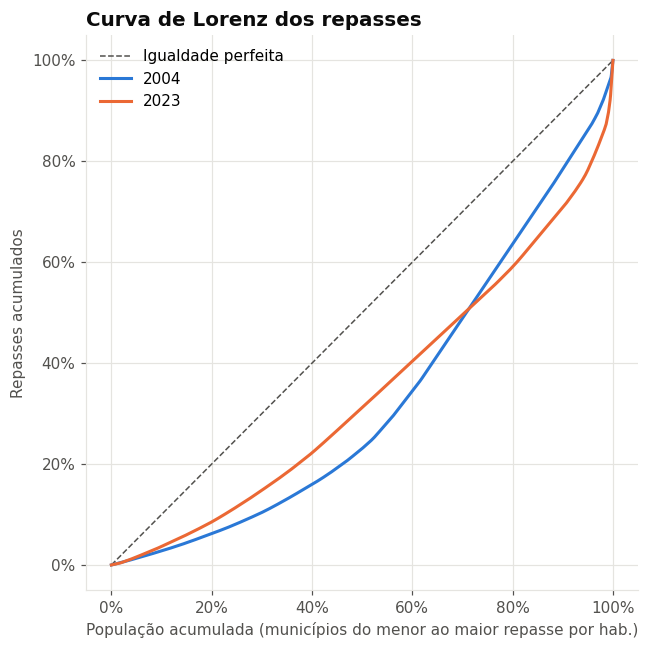

In [32]:
def lorenz(dados):
    d = dados.dropna(subset=['rep_total_pc']).sort_values('rep_total_pc')
    x = np.r_[0, d['populacao'].cumsum() / d['populacao'].sum()]
    y = np.r_[0, d['rep_total_real'].cumsum() / d['rep_total_real'].sum()]
    return x, y

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color=TEXTO_2, lw=1, ls='--', label='Igualdade perfeita')
for ano, cor in [(2004, AZUL), (2023, LARANJA)]:
    x, y = lorenz(base[base['ano'] == ano])
    ax.plot(x, y, color=cor, label=str(ano))
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set_xlabel('População acumulada (municípios do menor ao maior repasse por hab.)')
ax.set_ylabel('Repasses acumulados')
ax.set_title('Curva de Lorenz dos repasses')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Leitura:** as curvas de 2004 e 2023 **se cruzam**, porque duas coisas aconteceram ao mesmo tempo:
- **na base, melhorou:** a metade da população que mora nos municípios que menos recebem por habitante passou a
  ficar com uma fatia maior do dinheiro (a curva de 2023 fica mais perto da tracejada no começo);
- **no topo, piorou:** os poucos municípios campeões passaram a concentrar mais (a curva de 2023 se afasta da
  tracejada no fim).

O gráfico abaixo mostra a mesma informação de forma mais direta.

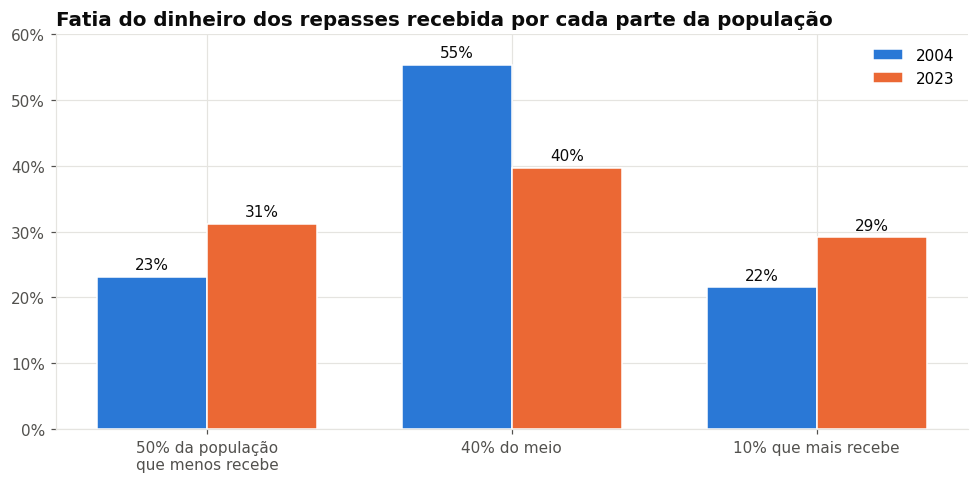

,2004,2023
50% da população\nque menos recebe,23.10,31.20
40% do meio,55.40,39.70
10% que mais recebe,21.50,29.10


In [33]:
def fatias_da_populacao(dados):
    """Fatia do dinheiro recebida pelos 50% da população de menor repasse/hab., pelos 40% do meio e pelos 10% do topo."""
    x, y = lorenz(dados)
    ate_50, ate_90 = np.interp(0.5, x, y), np.interp(0.9, x, y)
    return pd.Series({'50% da população\nque menos recebe': ate_50 * 100,
                      '40% do meio': (ate_90 - ate_50) * 100,
                      '10% que mais recebe': (1 - ate_90) * 100})

fatias = pd.DataFrame({ano: fatias_da_populacao(base[base['ano'] == ano]) for ano in [2004, 2023]})

fig, ax = plt.subplots(figsize=(9, 4.5))
posicoes = np.arange(len(fatias))
largura = 0.36
for deslocamento, ano, cor in [(-largura / 2, 2004, AZUL), (largura / 2, 2023, LARANJA)]:
    barras = ax.bar(posicoes + deslocamento, fatias[ano], width=largura, color=cor, label=str(ano),
                    edgecolor='white', linewidth=1)
    ax.bar_label(barras, labels=[f'{v:.0f}%' for v in fatias[ano]], padding=3, color=TEXTO)
ax.set_xticks(posicoes, fatias.index)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylim(0, 60)
ax.set_title('Fatia do dinheiro dos repasses recebida por cada parte da população')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

fatias.round(1)

### 5.3 Distribuição do repasse por habitante em 2023

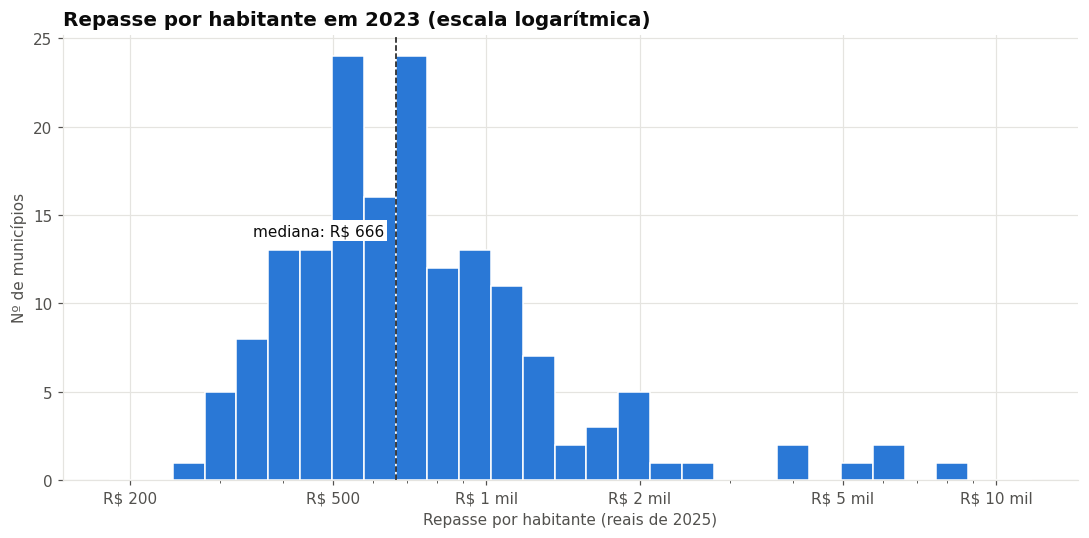

5 que mais recebem por habitante em 2023:
         municipio  rep_total_pc     pib_pc  pct_baixa_renda
           Guamaré     11,743.54 181,158.20            59.28
São Bento do Norte      8,447.54 128,609.81            68.56
      Pedra Grande      6,135.09  97,075.31            77.87
         Parazinho      6,020.76 118,149.68            77.00
          Galinhos      5,600.25  85,169.80            69.37

5 que menos recebem por habitante em 2023:
     municipio  rep_total_pc    pib_pc  pct_baixa_renda
      Extremoz        182.10 16,811.98            51.72
Nísia Floresta        278.47 19,074.22            54.36
  Monte Alegre        289.57 16,309.37            54.67
   Poço Branco        307.50 14,121.42            67.59
     Nova Cruz        315.32 19,759.53            63.65


In [34]:
d23 = base[base['ano'] == 2023]
fig, ax = plt.subplots()
ax.hist(d23['rep_total_pc'], bins=np.logspace(np.log10(d23['rep_total_pc'].min()),
                                             np.log10(d23['rep_total_pc'].max()), 30),
        color=AZUL, edgecolor='white', linewidth=1)
ax.set_xscale('log')
eixo_log_reais(ax.xaxis, MARCAS_REPASSE)
ax.axvline(d23['rep_total_pc'].median(), color=TEXTO, lw=1, ls='--')
ax.annotate(f"mediana: {reais(d23['rep_total_pc'].median())}", (d23['rep_total_pc'].median(), ax.get_ylim()[1] * 0.55),
            xytext=(-8, 0), textcoords='offset points', color=TEXTO, ha='right',
            bbox=dict(facecolor='white', edgecolor='none', pad=2))
ax.set_title('Repasse por habitante em 2023 (escala logarítmica)')
ax.set_xlabel('Repasse por habitante (reais de 2025)')
ax.set_ylabel('Nº de municípios')
plt.tight_layout()
plt.show()

print('5 que mais recebem por habitante em 2023:')
print(d23.nlargest(5, 'rep_total_pc')[['municipio', 'rep_total_pc', 'pib_pc', 'pct_baixa_renda']].to_string(index=False))
print('\n5 que menos recebem por habitante em 2023:')
print(d23.nsmallest(5, 'rep_total_pc')[['municipio', 'rep_total_pc', 'pib_pc', 'pct_baixa_renda']].to_string(index=False))

### 5.4 Ranking dos que mais recebem por habitante, ano a ano

Os 4 municípios com maior **ICMS por habitante** em cada ano (ICMS para incluir 2011). Diferente do valor total,
aqui o topo **muda ao longo do tempo**: Guamaré é o 1º em todos os anos, mas a partir de 2016 entram municípios
como Bodó, Parazinho, São Bento do Norte e Pedra Grande, no lugar de Areia Branca, Arez e Baía Formosa.

In [35]:
def top4(dados):
    d = dados.nlargest(4, 'rep_icms_pc')
    return pd.Series([f"{m} ({reais(v)})" for m, v in zip(d['municipio'], d['rep_icms_pc'])],
                     index=['1º', '2º', '3º', '4º'])

ranking_pc = base.groupby('ano')[['municipio', 'rep_icms_pc']].apply(top4)
ranking_pc

,1º,2º,3º,4º
ano,,,,
2004,"Guamaré (R$ 3,6 mil)","Galinhos (R$ 2,6 mil)","Areia Branca (R$ 1,1 mil)","Arez (R$ 1,1 mil)"
2005,"Guamaré (R$ 3,5 mil)","Galinhos (R$ 2,9 mil)","Arez (R$ 1,6 mil)","Areia Branca (R$ 1,2 mil)"
2006,"Guamaré (R$ 4,5 mil)","Galinhos (R$ 3,0 mil)","Arez (R$ 1,6 mil)","Areia Branca (R$ 1,2 mil)"
2007,"Guamaré (R$ 4,2 mil)","Galinhos (R$ 3,2 mil)","Arez (R$ 1,7 mil)","Baía Formosa (R$ 1,2 mil)"
2008,"Guamaré (R$ 4,1 mil)","Galinhos (R$ 2,9 mil)","Baía Formosa (R$ 1,9 mil)","Arez (R$ 1,4 mil)"
2009,"Guamaré (R$ 7,0 mil)","Galinhos (R$ 2,4 mil)","Baía Formosa (R$ 1,4 mil)","Arez (R$ 1,2 mil)"
2010,"Guamaré (R$ 9,8 mil)","Galinhos (R$ 2,7 mil)","Baía Formosa (R$ 1,8 mil)","Arez (R$ 1,4 mil)"
2011,Guamaré (R$ 11 mil),"Galinhos (R$ 3,2 mil)","Baía Formosa (R$ 2,2 mil)","Alto do Rodrigues (R$ 1,6 mil)"
2012,Guamaré (R$ 11 mil),"Galinhos (R$ 3,5 mil)","Baía Formosa (R$ 2,2 mil)","Arez (R$ 1,7 mil)"


In [36]:
# Quantas vezes cada município aparece entre os 4 primeiros (22 anos)
aparicoes = (base.groupby('ano').apply(lambda d: d.nlargest(4, 'rep_icms_pc'), include_groups=False)['municipio']
             .value_counts().rename('anos no top 4'))
aparicoes.to_frame()

,anos no top 4
municipio,
Guamaré,22
Galinhos,18
Arez,9
Parazinho,9
Baía Formosa,9
São Bento do Norte,6
Bodó,6
Areia Branca,3
Pedra Grande,3


## 6. Pergunta 2 — Os municípios mais pobres recebem mais ou menos?

### 6.1 Correlação ao longo do tempo

Correlação de Spearman entre o repasse por habitante e cada régua, ano a ano:
- **positiva com o PIB per capita** = quem produz mais riqueza recebe mais por habitante;
- **positiva com a % de baixa renda** = quem tem mais população pobre recebe mais por habitante.

O PIB negativo de Guamaré em 2012 fica fora dessas contas (coluna `pib_pc_analise`), porque o colocaria como o
município mais pobre do RN naquele ano.

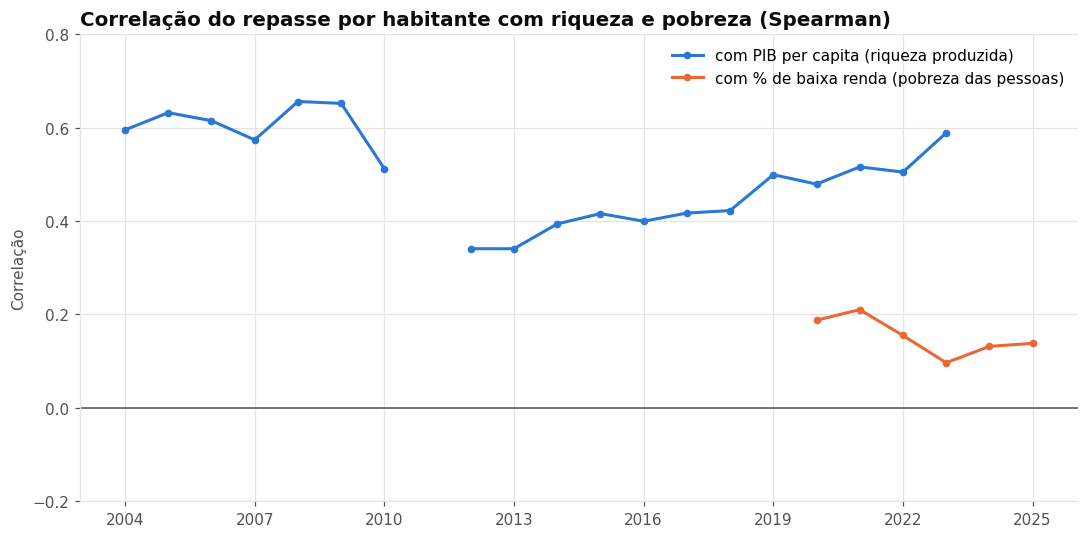

,com PIB per capita,com % baixa renda (CadÚnico)
2004,0.60,NaN
2008,0.66,NaN
2012,0.34,NaN
2016,0.40,NaN
2020,0.48,0.19
2023,0.59,0.10


In [37]:
correlacoes = pd.DataFrame({
    ano: {'com PIB per capita': d['rep_total_pc'].corr(d['pib_pc_analise'], method='spearman'),
          'com % baixa renda (CadÚnico)': d['rep_total_pc'].corr(d['pct_baixa_renda'], method='spearman')}
    for ano, d in base.groupby('ano')}).T

fig, ax = plt.subplots()
ax.plot(correlacoes.index, correlacoes['com PIB per capita'], color=AZUL, marker='o', markersize=4,
        label='com PIB per capita (riqueza produzida)')
ax.plot(correlacoes.index, correlacoes['com % baixa renda (CadÚnico)'], color=LARANJA, marker='o', markersize=4,
        label='com % de baixa renda (pobreza das pessoas)')
ax.axhline(0, color=TEXTO_2, lw=1)
ax.set_ylim(-0.2, 0.8)
ax.set_title('Correlação do repasse por habitante com riqueza e pobreza (Spearman)')
eixo_anos(ax)
ax.set_ylabel('Correlação')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

correlacoes.loc[[2004, 2008, 2012, 2016, 2020, 2023]].round(2)

### 6.2 Riqueza produzida × pobreza das pessoas (2023)

Cada ponto é um município. Os rotulados são os 3 que mais recebem por habitante: têm PIB per capita muito alto
(petróleo, eólicas, sal), mas boa parte da população está em baixa renda.

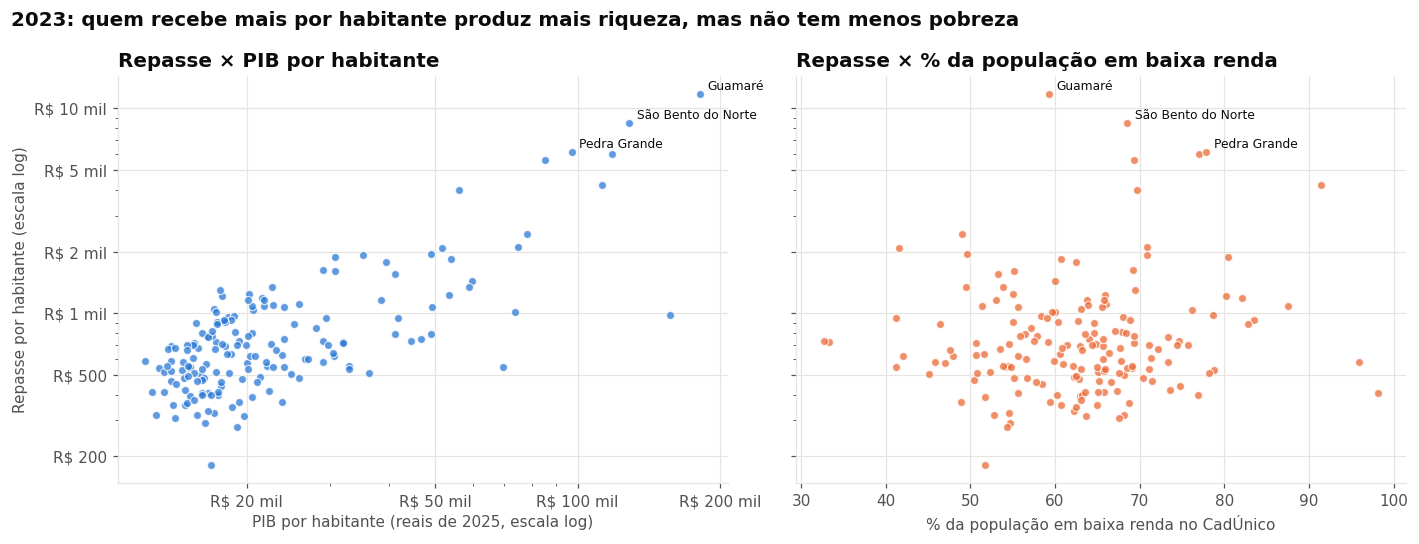

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
destaque = d23.nlargest(3, 'rep_total_pc')

for ax, coluna, titulo, cor in [
        (axes[0], 'pib_pc', 'Repasse × PIB por habitante', AZUL),
        (axes[1], 'pct_baixa_renda', 'Repasse × % da população em baixa renda', LARANJA)]:
    ax.scatter(d23[coluna], d23['rep_total_pc'], s=28, color=cor, alpha=0.75, edgecolor='white', linewidth=0.8)
    for _, m in destaque.iterrows():
        ax.annotate(m['municipio'], (m[coluna], m['rep_total_pc']), xytext=(5, 3), textcoords='offset points',
                    fontsize=8, color=TEXTO)
    ax.set_yscale('log')
    eixo_log_reais(ax.yaxis, MARCAS_REPASSE)
    ax.set_title(titulo)
axes[0].set_xscale('log')
eixo_log_reais(axes[0].xaxis, MARCAS_PIB)
axes[0].set_xlabel('PIB por habitante (reais de 2025, escala log)')
axes[1].set_xlabel('% da população em baixa renda no CadÚnico')
axes[0].set_ylabel('Repasse por habitante (escala log)')
fig.suptitle('2023: quem recebe mais por habitante produz mais riqueza, mas não tem menos pobreza',
             x=0.01, ha='left', fontsize=13, fontweight='bold', color=TEXTO)
plt.tight_layout()
plt.show()

### 6.3 Repasse por faixa de PIB per capita

Dividimos os municípios em 4 grupos de mesmo tamanho (quartis) pelo PIB per capita, em cada ano, e comparamos a
mediana do repasse por habitante.

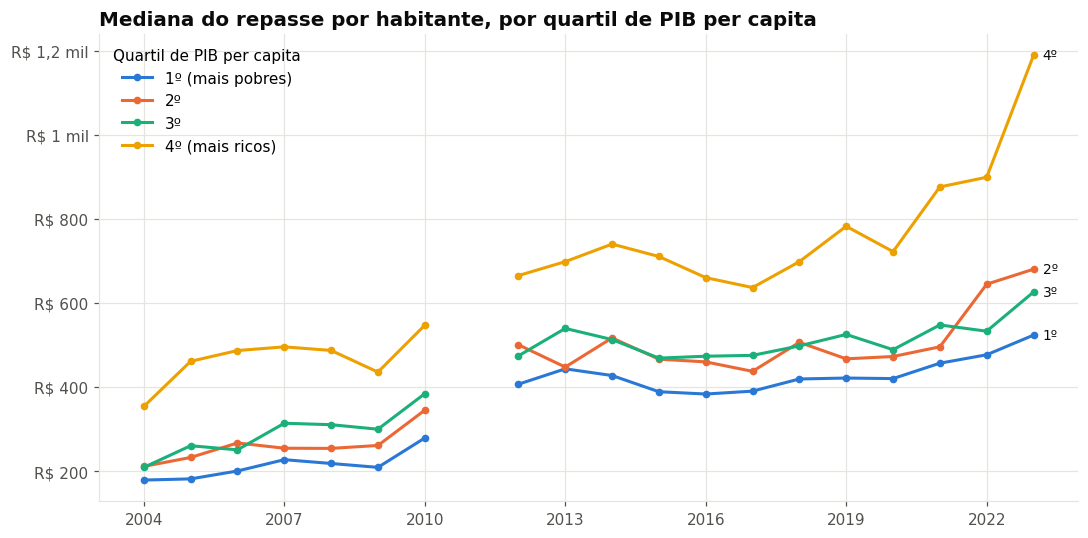

In [39]:
com_pib = base.dropna(subset=['pib_pc_analise', 'rep_total_pc']).copy()
com_pib['quartil_pib'] = com_pib.groupby('ano')['pib_pc_analise'].transform(
    lambda s: pd.qcut(s, 4, labels=['1º (mais pobres)', '2º', '3º', '4º (mais ricos)']))
quartis = (com_pib.pivot_table(index='ano', columns='quartil_pib', values='rep_total_pc', aggfunc='median',
                               observed=True)
           .reindex(range(base['ano'].min(), 2024)))       # mantém 2011 como buraco no gráfico

fig, ax = plt.subplots()
for coluna, cor in zip(quartis.columns, [AZUL, LARANJA, VERDE, AMARELO]):
    ax.plot(quartis.index, quartis[coluna], color=cor, marker='o', markersize=4, label=coluna)
    ax.annotate(coluna.split(' ')[0], (quartis[coluna].last_valid_index(), quartis[coluna].dropna().iloc[-1]), xytext=(6, 0),
                textcoords='offset points', color=TEXTO, va='center', fontsize=9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(reais))
ax.set_title('Mediana do repasse por habitante, por quartil de PIB per capita')
eixo_anos(ax)
ax.legend(title='Quartil de PIB per capita', loc='upper left')
plt.tight_layout()
plt.show()

**Complemento: a variação dentro de cada grupo (2004 × 2023)**

O gráfico de linhas mostra só a **mediana** de cada grupo. O boxplot abaixo mostra a **distribuição inteira** do
repasse por habitante dentro de cada quartil de PIB: a caixa vai do 1º ao 3º quartil do repasse, a linha preta é
a mediana e os pontos são os municípios fora do padrão.

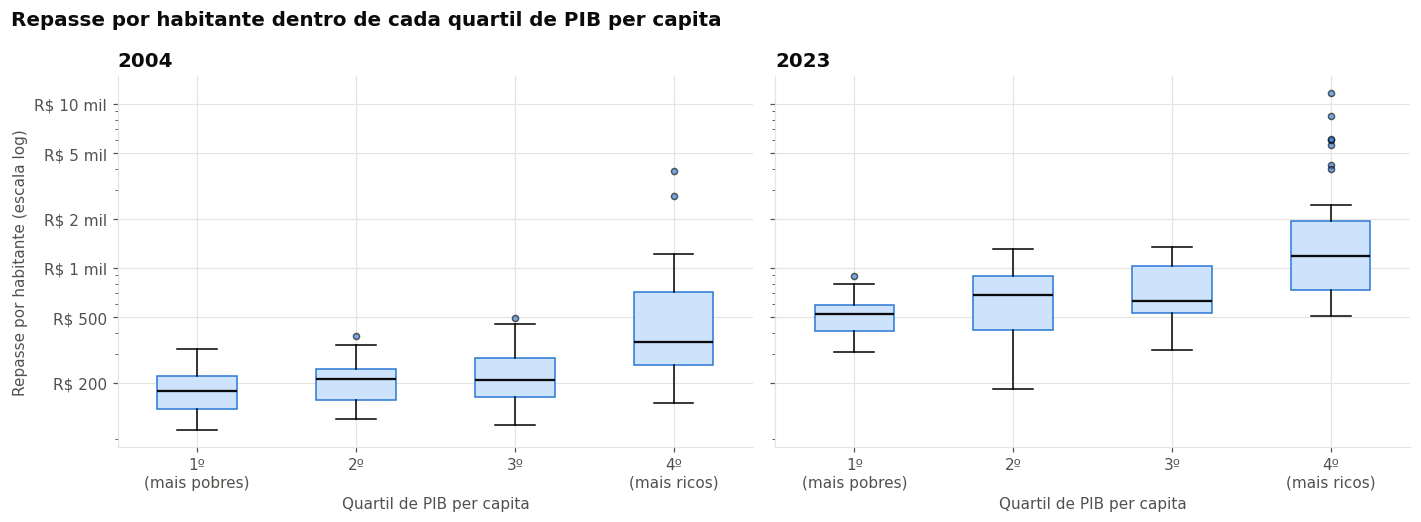

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, ano in zip(axes, [2004, 2023]):
    dados_ano = com_pib[com_pib['ano'] == ano]
    nomes = ['1º (mais pobres)', '2º', '3º', '4º (mais ricos)']
    grupos = [dados_ano.loc[dados_ano['quartil_pib'] == q, 'rep_total_pc'] for q in nomes]
    caixas = ax.boxplot(grupos, patch_artist=True, widths=0.5, medianprops=dict(color=TEXTO, lw=1.5),
                        flierprops=dict(marker='o', markersize=4, markerfacecolor=AZUL, alpha=0.6))
    for caixa in caixas['boxes']:
        caixa.set(facecolor='#cde2fb', edgecolor=AZUL)
    ax.set_xticks(range(1, len(nomes) + 1), [n.replace(' (', '\n(') for n in nomes])
    ax.set_yscale('log')
    eixo_log_reais(ax.yaxis, MARCAS_REPASSE)
    ax.set_title(str(ano))
    ax.set_xlabel('Quartil de PIB per capita')
axes[0].set_ylabel('Repasse por habitante (escala log)')
fig.suptitle('Repasse por habitante dentro de cada quartil de PIB per capita',
             x=0.01, ha='left', fontsize=13, fontweight='bold', color=TEXTO)
plt.tight_layout()
plt.show()

## 7. Pergunta 3 — Há concentração por região ou porte?

### 7.1 Por mesorregião

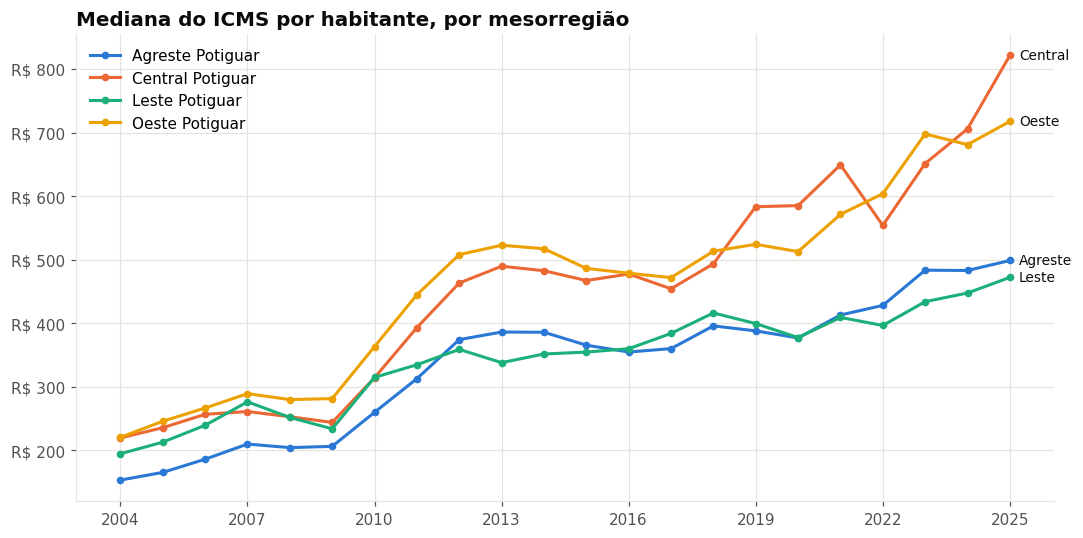

In [41]:
meso = base.pivot_table(index='ano', columns='mesorregiao', values='rep_icms_pc', aggfunc='median')
fig, ax = plt.subplots()
for coluna, cor in zip(meso.columns, [AZUL, LARANJA, VERDE, AMARELO]):
    ax.plot(meso.index, meso[coluna], color=cor, marker='o', markersize=4, label=coluna)
    ax.annotate(coluna.replace(' Potiguar', ''), (meso.index[-1], meso[coluna].iloc[-1]), xytext=(6, 0),
                textcoords='offset points', color=TEXTO, va='center', fontsize=9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(reais))
ax.set_title('Mediana do ICMS por habitante, por mesorregião')
eixo_anos(ax)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### 7.2 Por porte do município (2023)

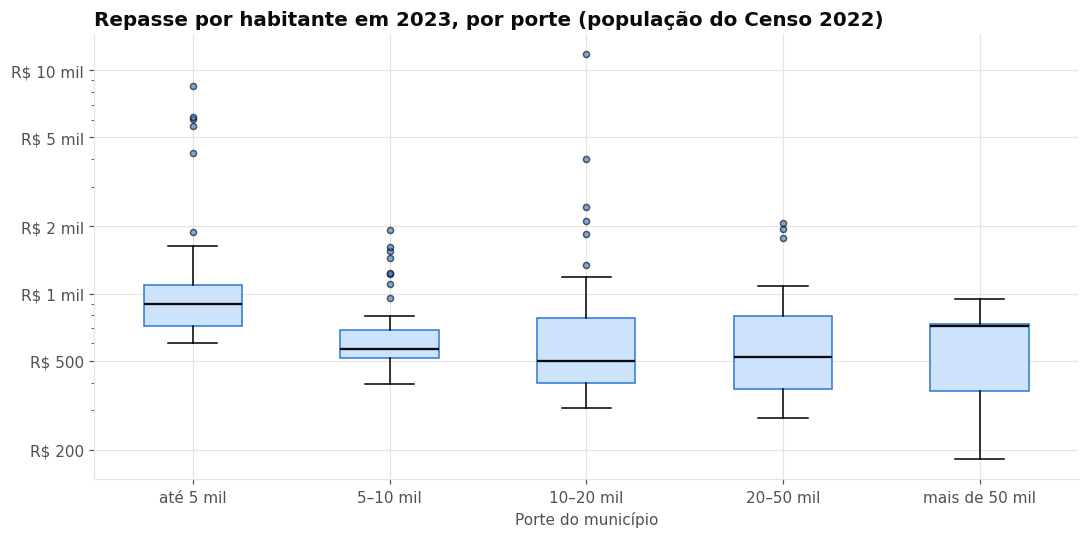

,municipios,mediana_repasse_pc,mediana_pib_pc,mediana_baixa_renda
porte,,,,
até 5 mil,52,900.78,"18,284.78",67.35
5–10 mil,47,562.84,"17,171.76",65.05
10–20 mil,41,501.25,"18,680.06",62.26
20–50 mil,18,521.21,"25,328.07",55.70
mais de 50 mil,9,715.92,"31,912.97",48.92


In [42]:
fig, ax = plt.subplots()
grupos = [d23.loc[d23['porte'] == p, 'rep_total_pc'] for p in d23['porte'].cat.categories]
caixas = ax.boxplot(grupos, patch_artist=True, widths=0.5,
                    medianprops=dict(color=TEXTO, lw=1.5), flierprops=dict(marker='o', markersize=4,
                                                                         markerfacecolor=AZUL, alpha=0.6))
for caixa in caixas['boxes']:
    caixa.set(facecolor='#cde2fb', edgecolor=AZUL)
ax.set_xticks(range(1, len(grupos) + 1), list(d23['porte'].cat.categories))
ax.set_yscale('log')
eixo_log_reais(ax.yaxis, MARCAS_REPASSE)
ax.set_title('Repasse por habitante em 2023, por porte (população do Censo 2022)')
ax.set_xlabel('Porte do município')
plt.tight_layout()
plt.show()

d23.groupby('porte', observed=True).agg(municipios=('cod_ibge', 'count'),
                                        mediana_repasse_pc=('rep_total_pc', 'median'),
                                        mediana_pib_pc=('pib_pc', 'median'),
                                        mediana_baixa_renda=('pct_baixa_renda', 'median'))

### 7.3 Concentração do valor total

Fatia do valor total dos repasses que vai para os 10 municípios que mais recebem em cada ano (em reais, não
por habitante).

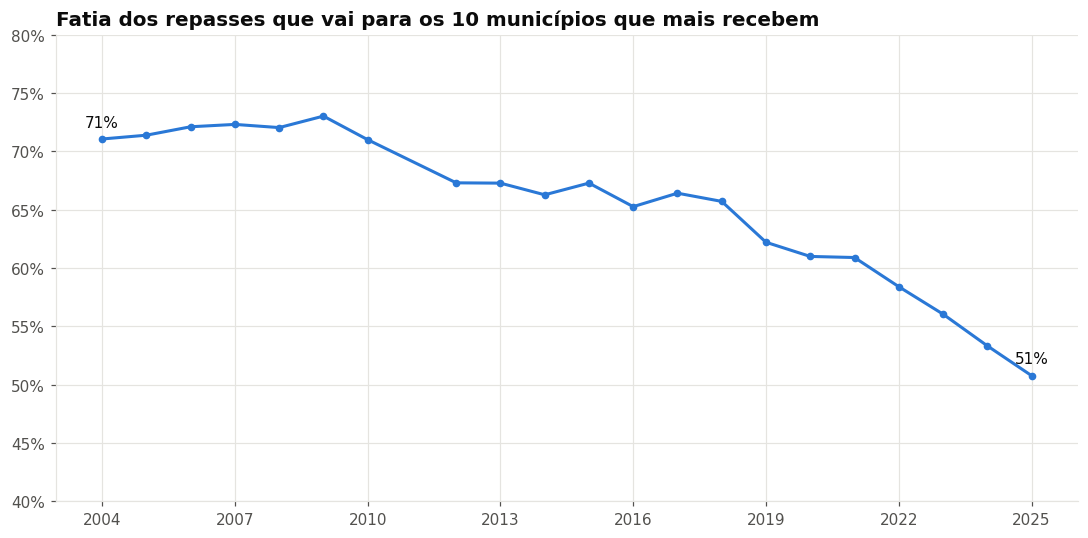

10 que mais receberam em 2004: Natal, Mossoró, Parnamirim, São Gonçalo do Amarante, Guamaré, Areia Branca, Macau, Macaíba, Caicó, Assú
10 que mais receberam em 2025: Natal, Mossoró, Parnamirim, Guamaré, Macau, Macaíba, Serra do Mel, Assú, Baraúna, Areia Branca


In [43]:
top10 = (base.dropna(subset=['rep_total']).groupby('ano')['rep_total']
         .apply(lambda s: s.nlargest(10).sum() / s.sum() * 100))
fig, ax = plt.subplots()
ax.plot(top10.index, top10.values, color=AZUL, marker='o', markersize=4)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylim(40, 80)
eixo_anos(ax)
ax.set_title('Fatia dos repasses que vai para os 10 municípios que mais recebem')
for ano in [top10.index[0], top10.index[-1]]:
    ax.annotate(f'{top10[ano]:.0f}%', (ano, top10[ano]), xytext=(0, 8), textcoords='offset points',
                ha='center', color=TEXTO)
plt.tight_layout()
plt.show()

print('10 que mais receberam em 2004:', ', '.join(base[base['ano'] == 2004].nlargest(10, 'rep_total')['municipio']))
print('10 que mais receberam em 2025:', ', '.join(base[base['ano'] == 2025].nlargest(10, 'rep_total')['municipio']))

In [44]:
quartis.loc[[2004, 2013, 2023]].round(0)

quartil_pib,1º (mais pobres),2º,3º,4º (mais ricos)
ano,,,,
2004,179.00,211.00,209.00,354.00
2013,443.00,447.00,539.00,698.00
2023,523.00,680.00,626.00,"1,189.00"


## 8. Principais achados

**Visão geral**
- Em valores reais (reais de 2025), os repasses obrigatórios **mais que dobraram**: de R$ 1,2 bilhão em 2004 para
  R$ 2,7 bilhões em 2023 (+118%). O **ICMS** responde por cerca de **86%** do total.

**Pergunta 1 — Desigualdade**
- O repasse por habitante é **bem desigual**: em 2023, os municípios do topo (90º percentil) recebem 4 vezes mais
  por habitante que os da base (10º percentil), e o maior valor (Guamaré, R$ 11,7 mil) é 64 vezes o menor
  (Extremoz, R$ 182).
- A desigualdade **caiu e depois subiu**: o Gini do total foi de 0,39 (2004) para 0,35 (2012–2013) e chegou a
  0,42–0,44 de 2020 em diante. **Hipótese a verificar:** a alta a partir de 2016 pode estar ligada aos municípios
  de **energia eólica**: é justamente a partir de 2016 que Bodó, Parazinho, São Bento do Norte e Pedra Grande
  entram entre os 4 que mais recebem por habitante (seção 5.4), no lugar de Areia Branca, Arez e Baía Formosa.
- **Guamaré** é o município que mais recebe por habitante em **todos os 22 anos**.

**Pergunta 2 — Ricos × pobres**
- Com o **PIB per capita**, a relação é **positiva em todos os anos** (correlação entre 0,34 e 0,66): quem produz
  mais riqueza recebe mais por habitante. O quartil mais rico recebe cerca de **2 vezes** o mais pobre, e essa
  distância aumentou em 2023.
- Com a **pobreza das pessoas** (CadÚnico, 2020–2025), a relação é **fraca** (0,10 a 0,21): o repasse quase não
  acompanha a proporção de população pobre.
- Os campeões de repasse por habitante (Guamaré, São Bento do Norte, Pedra Grande, Parazinho, Galinhos) têm PIB
  per capita altíssimo por causa de petróleo, sal e eólicas, mas **59% a 78% da população em baixa renda**.
  Ou seja: os repasses seguem a **riqueza produzida no território**, não a **necessidade da população**. Faz
  sentido, porque a cota-parte do ICMS é repartida principalmente pelo valor adicionado gerado em cada município.

**Pergunta 3 — Região e porte**
- **Central** e **Oeste Potiguar** (onde estão petróleo, sal e eólicas) recebem mais por habitante que **Leste** e
  **Agreste**, e a distância cresceu desde 2010.
- Os municípios **pequenos** (até 5 mil habitantes) têm a maior mediana de repasse por habitante.
- Em **valor total**, os maiores recebedores quase não mudam: **Natal, Mossoró e Parnamirim** estão entre os 4
  maiores em todos os anos, e **Guamaré** desde 2008 (seção 4.3). Mas a concentração **diminuiu**: os 10 que mais
  recebem ficavam com 71% do total em 2004 e com 51% em 2025, e os demais municípios ganharam espaço. A fatia de
  **Natal** no ICMS caiu de 36% para 16%.

**Limitações**
- 2011 só tem ICMS; PIB só até 2023; CadÚnico só de 2020 a 2025 (API do MDS fora do ar).
- A população vem de estimativas, Contagem e Censos, com "degraus" (2007, 2010, 2013, 2018, 2022) que afetam os
  valores per capita.
- O PIB de municípios petroleiros é instável (Guamaré teve PIB negativo em 2012, mantido na base como atípico).
- Correlação não é causa: as análises descrevem a distribuição, não explicam a regra de repartição.